# Прогнозиране на качеството на вино чрез методи за класификация

Курсов проект по извличане на знания от данни. Задачата е **supervised classification**:
по физикохимични измервания на вино да се предскаже качественият клас.

Източник на данните: UCI *Wine Quality* — Cortez et al. (2009), португалско *Vinho Verde*.


## 1. Идея и постановка

```
физикохимични измервания
          ↓
   предварителна обработка
          ↓
   train / test split
          ↓
   избор на признаци
          ↓
   Decision Tree · k-NN · Random Forest
          ↓
      предсказване
          ↓
     оценка (accuracy, precision, recall, F1, confusion matrix)
          ↓
     сравнение на моделите
```

Оригиналната оценка е цяло число от 0 до 10, но класовете са силно небалансирани
(почти всички проби са 5 или 6). Затова целевата променлива се прекодира в три класа:

| Клас | Оригинална оценка | Смисъл |
| --- | --- | --- |
| ниско | ≤ 4 | слабо вино |
| средно | 5–6 | типично вино |
| високо | ≥ 7 | добро вино |


## 2. Зареждане на данните и предварителна обработка


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
CLASS_ORDER = ["ниско", "средно", "високо"]

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

red = pd.read_csv(ROOT / "data" / "winequality-red.csv", sep=";")
white = pd.read_csv(ROOT / "data" / "winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0
df = pd.concat([red, white], ignore_index=True)

def quality_to_class(q: int) -> str:
    if q <= 4:
        return "ниско"
    if q <= 6:
        return "средно"
    return "високо"

df["quality_class"] = df["quality"].map(quality_to_class)
features = [c for c in df.columns if c not in {"quality", "quality_class"}]

print(df.shape)
print("липсващи стойности:", int(df.isna().sum().sum()))
df.head()


(6497, 14)
липсващи стойности: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red,quality_class
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1,средно
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,средно
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1,средно
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1,средно
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1,средно


Няма липсващи стойности. Червеното и бялото вино се обединяват в една таблица;
признакът `is_red` пази типа, защото химичният профил на двата стила се различава.


In [2]:
print("червено / бяло:", int(df.is_red.sum()), "/", int((df.is_red == 0).sum()))
print("\nоригинална оценка:")
print(df["quality"].value_counts().sort_index())
print("\nкласове:")
print(df["quality_class"].value_counts().reindex(CLASS_ORDER))
df[features].describe().T[["mean", "std", "min", "max"]].round(3)


червено / бяло: 1599 / 4898

оригинална оценка:
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

класове:
quality_class
ниско      246
средно    4974
високо    1277
Name: count, dtype: int64


,mean,std,min,max
fixed acidity,7.215,1.296,3.800,15.900
volatile acidity,0.340,0.165,0.080,1.580
citric acid,0.319,0.145,0.000,1.660
residual sugar,5.443,4.758,0.600,65.800
chlorides,0.056,0.035,0.009,0.611
free sulfur dioxide,30.525,17.749,1.000,289.000
total sulfur dioxide,115.745,56.522,6.000,440.000
density,0.995,0.003,0.987,1.039
pH,3.219,0.161,2.720,4.010
sulphates,0.531,0.149,0.220,2.000


## 3. Изследователски анализ


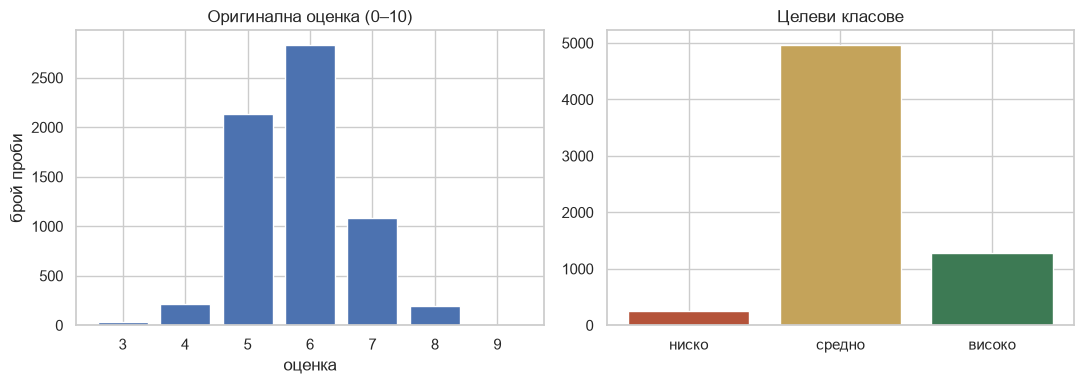

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orig = df["quality"].value_counts().sort_index()
axes[0].bar(orig.index.astype(str), orig.values)
axes[0].set_title("Оригинална оценка (0–10)")
axes[0].set_xlabel("оценка")
axes[0].set_ylabel("брой проби")

cls = df["quality_class"].value_counts().reindex(CLASS_ORDER)
axes[1].bar(cls.index, cls.values, color=["#b4533a", "#c4a35a", "#3d7a54"])
axes[1].set_title("Целеви класове")
plt.tight_layout()
plt.show()


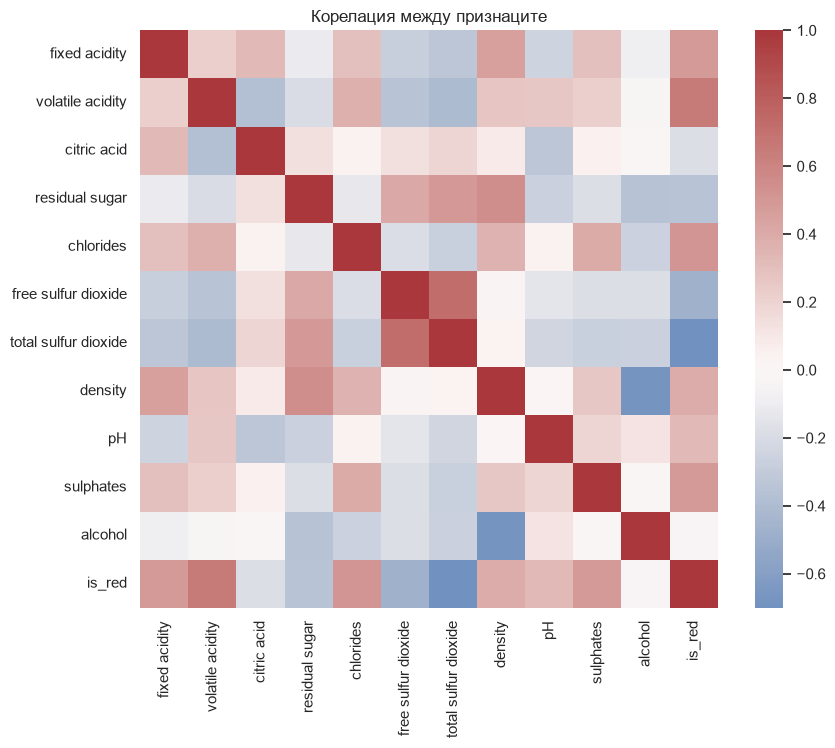

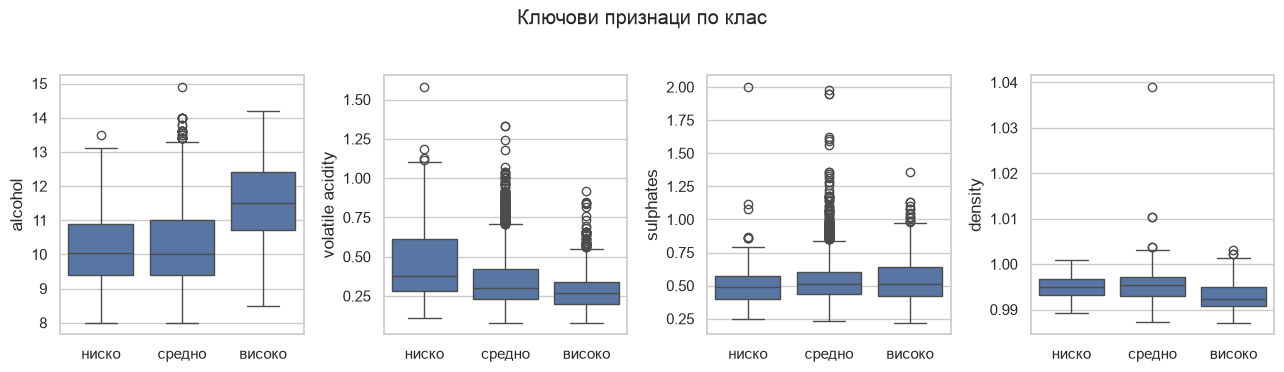

In [4]:
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(df[features].corr(numeric_only=True), cmap="vlag", center=0, square=True)
plt.title("Корелация между признаците")
plt.show()

keys = ["alcohol", "volatile acidity", "sulphates", "density"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, col in zip(axes, keys):
    sns.boxplot(data=df, x="quality_class", y=col, order=CLASS_ORDER, ax=ax)
    ax.set_xlabel("")
fig.suptitle("Ключови признаци по клас", y=1.03)
plt.tight_layout()
plt.show()


Наблюдения от EDA:

- **дисбаланс** — клас „средно“ е около 76% от извадката; accuracy над 76% не е успех сам по себе си
- **алкохолът** расте с качеството; **летливата киселинност** е по-висока при слабото вино
- **корелации** — `free sulfur dioxide` с `total sulfur dioxide` (0.72), `density` с `alcohol` (−0.69)


## 4. Обучаваща и тестова извадка


In [5]:
X = df[features]
y = df["quality_class"].map({n: i for i, n in enumerate(CLASS_ORDER)}).to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, "test:", X_test.shape)
print("дял на класовете в train:", np.bincount(y_train) / len(y_train))
print("дял на класовете в test: ", np.bincount(y_test) / len(y_test))


train: (5197, 12) test: (1300, 12)
дял на класовете в train: [0.03790648 0.76563402 0.1964595 ]
дял на класовете в test:  [0.03769231 0.76538462 0.19692308]


Разделянето е **стратифицирано** (80/20), за да се запази съотношението на класовете.
Всички хиперпараметри се избират **само върху train** чрез 5-fold stratified cross-validation.
Тестовата извадка се пипа еднократно в края.


## 5. Избор на признаци


In [6]:
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
ranking = pd.DataFrame({"признак": features, "mutual_info": mi}).sort_values(
    "mutual_info", ascending=False
)
display(ranking.round(4))

selector = SelectKBest(score_func=f_classif, k=8)
selector.fit(X_train, y_train)
selected = X_train.columns[selector.get_support()].tolist()
print("SelectKBest (ANOVA F), k=8:", selected)


,признак,mutual_info
10,alcohol,0.0975
7,density,0.0881
6,total sulfur dioxide,0.0411
4,chlorides,0.0366
3,residual sugar,0.0290
1,volatile acidity,0.0285
2,citric acid,0.0246
0,fixed acidity,0.0242
5,free sulfur dioxide,0.0193
9,sulphates,0.0190


SelectKBest (ANOVA F), k=8: ['volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'alcohol', 'is_red']


`mutual_info_classif` и `SelectKBest(f_classif)` са два класически филтърни метода.
Алкохолът и плътността водят класацията. По-късно Random Forest се преобучава и върху
8-те ANOVA признака, за да се види дали по-малък набор влошава качеството.


## 6. Модели, кръстосана валидация и хиперпараметри

Три алгоритъма + базов класификатор (винаги предсказва мнозинството):

| Модел | Защо е в курса | Какво се настройва |
| --- | --- | --- |
| Dummy / majority | долна граница при дисбаланс | — |
| Decision Tree | интерпретируеми правила | `max_depth`, `min_samples_split`, `criterion` |
| k-NN | метричен метод; задължително скалиране | `n_neighbors`, `weights`, `p` |
| Random Forest | ансамбъл от дървета | `n_estimators`, `max_depth`, `min_samples_leaf` |

Оптимизационната мярка е **F1-macro**, не accuracy: така редките класове „ниско“ и „високо“
не се игнорират. Дърветата използват `class_weight="balanced"`. k-NN е в `Pipeline` със
`StandardScaler`, защото разстоянията зависят от мащаба на признаците.


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

tree_cv = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    {
        "max_depth": [4, 8, 12, None],
        "min_samples_split": [2, 10, 20],
        "criterion": ["gini", "entropy"],
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
knn_cv = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
    {
        "clf__n_neighbors": [3, 5, 9, 15],
        "clf__weights": ["uniform", "distance"],
        "clf__p": [1, 2],
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)
forest_cv = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    {
        "n_estimators": [100, 200],
        "max_depth": [10, 20, None],
        "min_samples_leaf": [1, 3],
        "max_features": ["sqrt", "log2"],
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
)

tree_cv.fit(X_train, y_train)
knn_cv.fit(X_train, y_train)
forest_cv.fit(X_train, y_train)

print("Decision Tree", tree_cv.best_params_, "CV F1-macro", round(tree_cv.best_score_, 4))
print("k-NN         ", knn_cv.best_params_, "CV F1-macro", round(knn_cv.best_score_, 4))
print("Random Forest", forest_cv.best_params_, "CV F1-macro", round(forest_cv.best_score_, 4))


Decision Tree {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2} CV F1-macro 0.5467
k-NN          {'clf__n_neighbors': 3, 'clf__p': 2, 'clf__weights': 'distance'} CV F1-macro 0.5847
Random Forest {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200} CV F1-macro 0.6183


## 7. Оценка върху тестовата извадка


,модел,accuracy,precision_macro,recall_macro,f1_macro
0,Baseline (majority),0.7654,0.2551,0.3333,0.2890
1,Decision Tree,0.7954,0.5929,0.5723,0.5794
2,k-NN,0.8162,0.6862,0.5926,0.6175
3,Random Forest,0.7831,0.5966,0.6499,0.6156


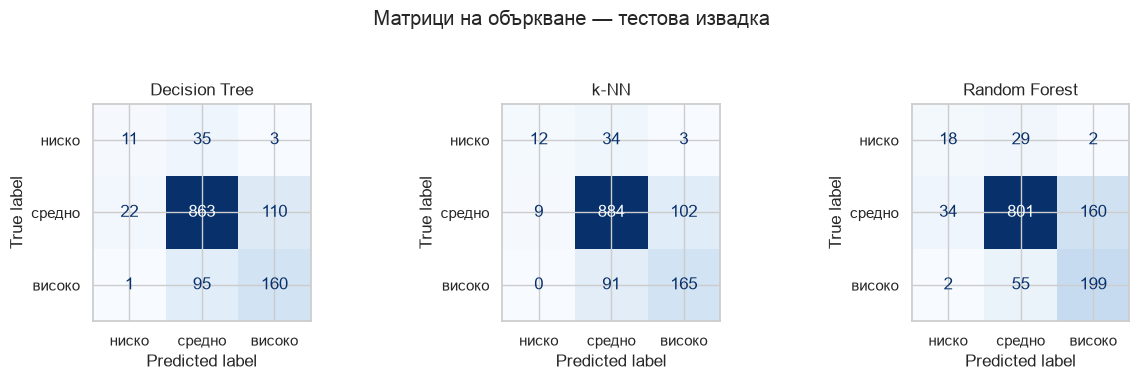

              precision    recall  f1-score   support

       ниско       0.33      0.37      0.35        49
      средно       0.91      0.81      0.85       995
      високо       0.55      0.78      0.65       256

    accuracy                           0.78      1300
   macro avg       0.60      0.65      0.62      1300
weighted avg       0.81      0.78      0.79      1300



In [8]:
def evaluate(name, model, X_eval=None):
    X_eval = X_test if X_eval is None else X_eval
    pred = model.predict(X_eval)
    return {
        "модел": name,
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision_macro": round(precision_score(y_test, pred, average="macro", zero_division=0), 4),
        "recall_macro": round(recall_score(y_test, pred, average="macro", zero_division=0), 4),
        "f1_macro": round(f1_score(y_test, pred, average="macro"), 4),
        "pred": pred,
    }

results = [
    evaluate("Baseline (majority)", dummy),
    evaluate("Decision Tree", tree_cv.best_estimator_),
    evaluate("k-NN", knn_cv.best_estimator_),
    evaluate("Random Forest", forest_cv.best_estimator_),
]
display(pd.DataFrame([{k: v for k, v in row.items() if k != "pred"} for row in results]))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, row in zip(axes, results[1:]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, row["pred"], display_labels=CLASS_ORDER, cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(row["модел"])
fig.suptitle("Матрици на объркване — тестова извадка", y=1.05)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    results[-1]["pred"],
    target_names=CLASS_ORDER,
    zero_division=0,
))


## 8. Сравнение на алгоритмите и важност на признаците


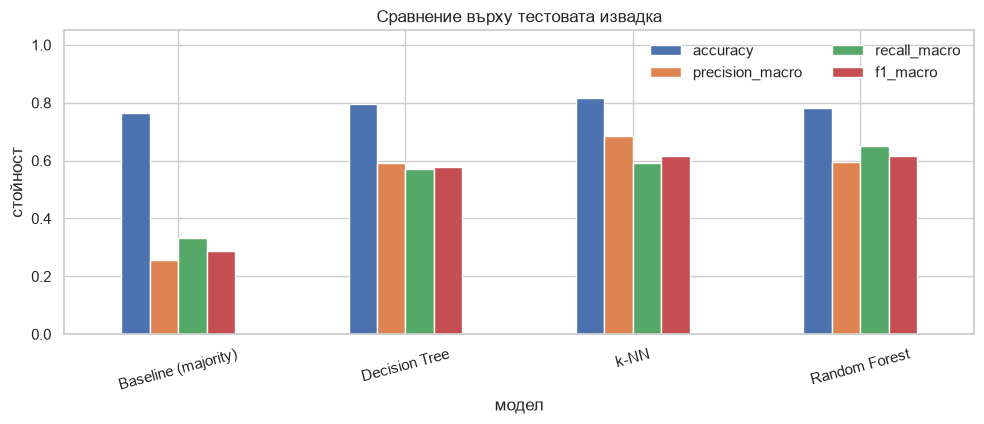

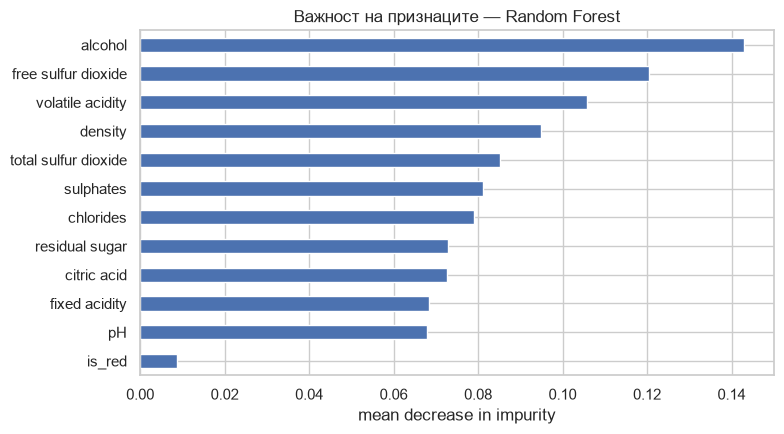

пълен набор F1-macro: 0.6156
SelectKBest k=8 F1-macro: 0.611


In [9]:
metric_names = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
plot_df = pd.DataFrame(results).set_index("модел")[metric_names]
plot_df.plot(kind="bar", figsize=(10, 4.4), ylim=(0, 1.05))
plt.ylabel("стойност")
plt.title("Сравнение върху тестовата извадка")
plt.xticks(rotation=15)
plt.legend(ncol=2, frameon=False)
plt.tight_layout()
plt.show()

importances = pd.Series(
    forest_cv.best_estimator_.feature_importances_, index=features
).sort_values()
importances.plot(kind="barh", figsize=(8, 4.5), title="Важност на признаците — Random Forest")
plt.xlabel("mean decrease in impurity")
plt.tight_layout()
plt.show()

# аблация: същите хиперпараметри, но само 8 ANOVA признака
forest_sel = RandomForestClassifier(
    **forest_cv.best_params_,
    random_state=RANDOM_STATE,
    class_weight="balanced",
)
forest_sel.fit(X_train[selected], y_train)
sel = evaluate("Random Forest (k=8)", forest_sel, X_test[selected])
print("пълен набор F1-macro:", results[-1]["f1_macro"])
print("SelectKBest k=8 F1-macro:", sel["f1_macro"])


## 9. Интерпретация на резултатите

Числата по-долу са от фиксирания seed `random_state=42` (повтаря се и в `src/wine_quality.py`).

| Модел | Accuracy | Precision macro | Recall macro | F1 macro | CV F1 macro |
| --- | ---: | ---: | ---: | ---: | ---: |
| Baseline (majority) | 0.765 | 0.255 | 0.333 | 0.289 | — |
| Decision Tree | 0.795 | 0.593 | 0.572 | 0.579 | 0.547 |
| k-NN | **0.816** | **0.686** | 0.593 | **0.618** | 0.585 |
| Random Forest | 0.783 | 0.597 | **0.650** | 0.616 | **0.618** |

Какво следва от таблицата:

1. **Accuracy лъже.** Базовият модел вече има 76.5% точност, защото винаги казва „средно“.
   Затова сравнението се прави по F1-macro.
2. **Decision Tree** с `max_depth=None` запаметява обучаващата извадка (train F1 = 1.0) и
   генерализира най-слабо. Това е класически пример за overfitting.
3. **k-NN** (`k=3`, разстояние на Евклид, тегла `distance`) има най-висока тестова точност и
   F1-macro. Скалното нормализиране е задължително; без него признаци като `total sulfur dioxide`
   биха доминирали разстоянието.
4. **Random Forest** печели кросвалидацията и **recall** за редките класове: открива 37% от
   слабото и 78% от доброто вино (срещу 24% и 64% при k-NN). Това го прави по-полезен, ако целта
   е да не се пропускат крайните качества.
5. **Изборът на 8 признака** почти не влошава Random Forest (F1-macro 0.616 → 0.611). Най-важният
   признак и при MI, и при impurity importance е **алкохолът**.

Матриците на объркване показват един и същ типичен грешен ход: „ниско“ се бърка със „средно“.
Това е очаквано — между оценка 4 и 5 границата е тънка, а пробите с ниско качество са малко (246 от 6497).


## 10. Какво демонстрира проектът спрямо курса

| Тема от курса | Къде е в проекта |
| --- | --- |
| Supervised learning | целеви клас `quality_class` е известен при обучение |
| Classification | три класа, не регресия |
| Train / test | стратифициран 80/20 split |
| Cross-validation | `StratifiedKFold(5)` |
| Feature selection | mutual information + ANOVA `SelectKBest` |
| Hyperparameter selection | `GridSearchCV` с мярка `f1_macro` |
| Decision trees | `DecisionTreeClassifier` |
| k-NN | `KNeighborsClassifier` в pipeline със scaler |
| Random Forest | ансамбъл и feature importance |
| Accuracy / precision / recall / F1 | макро осредняване заради дисбаланса |
| Confusion matrix | по един heatmap на модел |
| Comparison of algorithms | обща таблица + baseline |

Цитиране на данните: P. Cortez, A. Cerdeira, F. Almeida, T. Matos, J. Reis.
*Modeling wine preferences by data mining from physicochemical properties.*
Decision Support Systems, 47(4):547–553, 2009.
